In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import cartopy.crs as ccrs
import geopandas
from cartopy.io import shapereader
countries_polygons = geopandas.read_file(shapereader.natural_earth(resolution='10m', category='cultural', name='admin_0_countries'))

species_list = ['Abies_alba', 'Acer_campestre', 'Acer_pseudoplatanus', 'Alnus_glutinosa', 'Alnus_incana', 'Betula_pendula', 'Betula_pubescens', 'Carpinus_betulus', 'Corylus_avellana', 'Fagus_sylvatica', 'Fraxinus_excelsior', 'Picea_abies', 'Pinus_halepensis', 'Pinus_nigra', 'Pinus_pinaster', 'Pinus_sylvestris', 'Populus_tremula', 'Prunus_avium', 'Quercus_ilex', 'Quercus_petraea', 'Quercus_pubescens', 'Quercus_robur', 'Quercus_suber', 'Sorbus_aucuparia']

# bands start at 1, not 0!
band_names = {1: 'historical', 2: 'present', 5: 'ssp1', 6: 'ssp1a', 9: 'ssp2', 10: 'ssp2a', 13: 'ssp5', 14: 'ssp5a'}
scenarios = list(band_names.values())


CLIMATE_DATA_RES = 0.0083333

import amoc_computations as amoc_comp
import amoc_plots
import importlib

<module 'amoc_plots' from '/home/konni/Documents/phd/amoc_forestry/amoc_plots.py'>

# Heubel occurrences

In [11]:
heubel = pd.read_csv('data/heubel_occurrences.csv', sep=',')

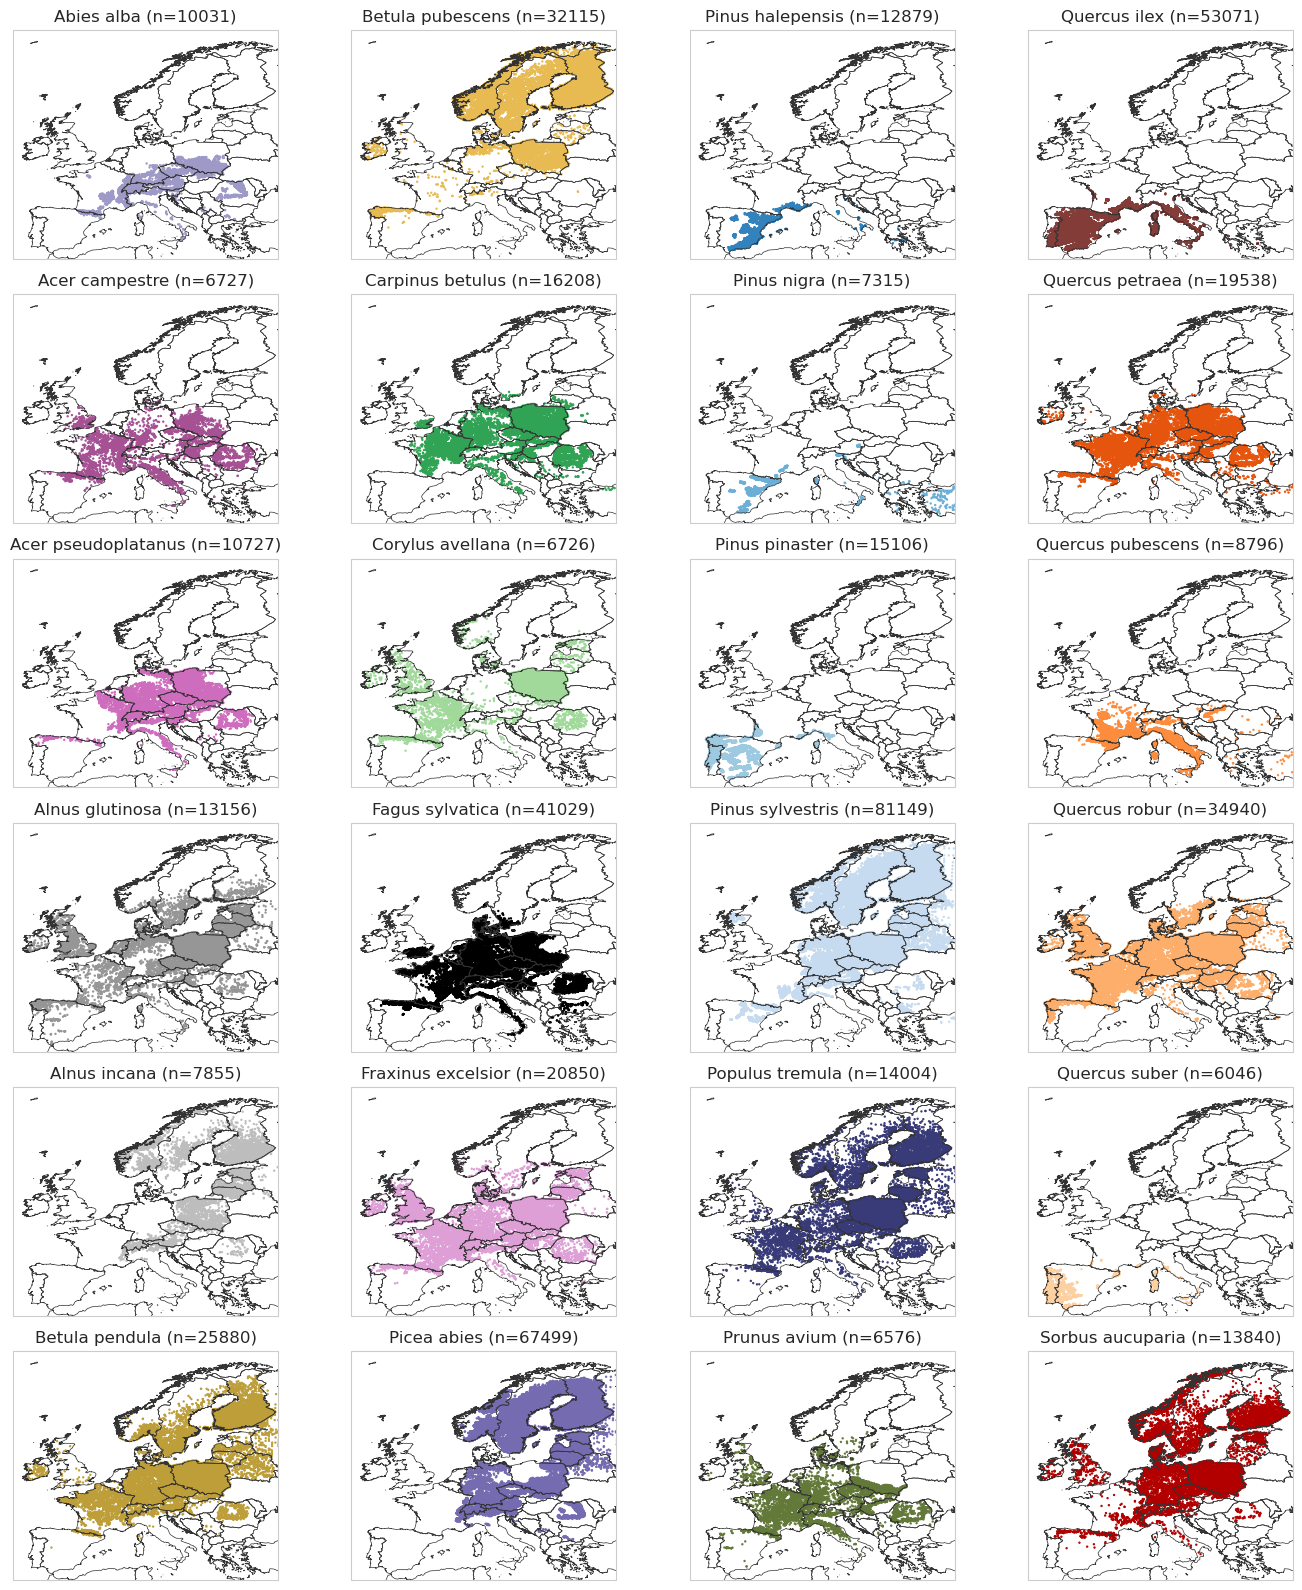

In [12]:
heubel.rename(columns={'LON': 'lon', 'LAT': 'lat'}, inplace=True)

heubel['SPECIES_NAME_NORM'] = heubel['species'].str.replace(' ', '_')
heubel_amoc_species = heubel[heubel['SPECIES_NAME_NORM'].isin(species_list)].copy()
heubel_amoc_species = heubel_amoc_species[heubel_amoc_species['lat'] > 36] # cut out canary islands etc
heubel_amoc_species['opt_single_species'] = heubel_amoc_species['SPECIES_NAME_NORM'].map(lambda x: species_list.index(x))
importlib.reload(amoc_plots)

fig, ax = plt.subplots(6, 4, figsize=(14, 16), subplot_kw={'projection': ccrs.PlateCarree()})

species_id = 0
for j in range(4):
    for i in range(6):
        current_species_name = species_list[species_id]
        current_species_occurrences = heubel_amoc_species[
            heubel_amoc_species['SPECIES_NAME_NORM'] == current_species_name]

        amoc_plots.plot_single_best_species(ax[i][j],
                                            current_species_occurrences.rename(columns={'lon': 'x', 'lat': 'y'}),
                                            species_list, s=0.5,
                                            title=current_species_name.replace('_', ' ') + ' (n=' + str(
                                                len(current_species_occurrences)) + ')', colorbar=False)
        species_id += 1

plt.tight_layout()

# Number of suitable species

In [13]:
df_final_from_disk = pd.read_csv('data/all_data_newamoc_with_present_and_historical_every_100.csv', sep=';')

In [14]:
df_uncertainty = df_final_from_disk.copy().reset_index()
for i, scenario in enumerate(scenarios):
    scenario_cols = [col for col in df_uncertainty.columns if col.endswith(f'-{scenario}')]
    df_uncertainty[f'num_species_gt0_{scenario}'] = (df_uncertainty[scenario_cols] > 0).sum(axis=1)

species_with_positive_historical = []
species_with_positive_present = []
species_with_positive_all_scenarios = []
species_with_positive_all_scenarios_and_present = []
species_with_positive_ssp125_on_scenarios = []
species_with_positive_ssp125_off_scenarios = []
species_with_positive_ssp12_scenarios = []
species_with_positive_ssp1_scenarios = []
for sp in species_list:
    species_with_positive_historical.append((df_uncertainty[[sp + '-historical']] > 0).all(axis=1))

    species_with_positive_present.append((df_uncertainty[[sp + '-present']] > 0).all(axis=1))

    species_with_positive_ssp1_scenarios.append((df_uncertainty[[sp + '-ssp1']] > 0).all(axis=1))

    species_with_positive_ssp12_scenarios.append((df_uncertainty[[sp + '-ssp1', sp + '-ssp2']] > 0).all(axis=1))

    species_with_positive_ssp125_on_scenarios.append((df_uncertainty[[sp + '-ssp1', sp + '-ssp2', sp + '-ssp5']] > 0).all(axis=1))

    species_with_positive_ssp125_off_scenarios.append((df_uncertainty[[sp + '-ssp1a', sp + '-ssp2a', sp + '-ssp5a']] > 0).all(axis=1))

    sp_cols_scenarios = [col for col in df_uncertainty.columns if col.startswith(f'{sp}-') and 'ssp' in col]
    species_with_positive_all_scenarios.append((df_uncertainty[sp_cols_scenarios] > 0).all(axis=1))

    sp_cols_scenarios_and_present = [col for col in df_uncertainty.columns if col.startswith(f'{sp}-') and not col.endswith('historical')]
    species_with_positive_all_scenarios_and_present.append((df_uncertainty[sp_cols_scenarios_and_present] > 0).all(axis=1))

# Concatenate all the masks and sum along species
df_uncertainty['num_species_suitable_in_all_scenarios'] = pd.concat(species_with_positive_all_scenarios, axis=1).sum(axis=1)
df_uncertainty['num_species_suitable_in_all_scenarios_and_present'] = pd.concat(species_with_positive_all_scenarios_and_present, axis=1).sum(axis=1)
df_uncertainty['num_species_suitable_in_ssp125_scenarios'] = pd.concat(species_with_positive_ssp125_on_scenarios, axis=1).sum(axis=1)
df_uncertainty['num_species_suitable_in_ssp125_off_scenarios'] = pd.concat(species_with_positive_ssp125_off_scenarios, axis=1).sum(axis=1)
df_uncertainty['num_species_suitable_in_ssp12_scenarios'] = pd.concat(species_with_positive_ssp12_scenarios, axis=1).sum(axis=1)
df_uncertainty['num_species_suitable_in_ssp1_scenarios'] = pd.concat(species_with_positive_ssp1_scenarios, axis=1).sum(axis=1)
df_uncertainty['num_species_suitable_in_present'] = pd.concat(species_with_positive_present, axis=1).sum(axis=1)
df_uncertainty['num_species_suitable_in_historical'] = pd.concat(species_with_positive_historical, axis=1).sum(axis=1)

In [15]:
col_list = {
    'num_species_suitable_in_present': 'present',
    'num_species_suitable_in_ssp1_scenarios': 'ssp126',
    'num_species_suitable_in_ssp125_scenarios': 'all standard scenarios',
    'num_species_suitable_in_ssp125_off_scenarios': 'all AMOC shutdown scenarios',
    'num_species_suitable_in_all_scenarios': 'all scenarios',
}

In [16]:
df_uncertainty['area'] = df_uncertainty['y'].map(lambda x: amoc_comp.get_area_for_lon_and_lat_with_formulas_specific_gc_size(x, CLIMATE_DATA_RES, CLIMATE_DATA_RES))
total_weighted_means = {
    col: (df_uncertainty[col] * df_uncertainty['area']).sum() / df_uncertainty['area'].sum()
    for col in col_list.keys()
}
total_weighted_std = {
    col: np.sqrt(
        (
                df_uncertainty['area'] *
                (df_uncertainty[col] - total_weighted_means[col])**2
        ).sum() / df_uncertainty['area'].sum()
    )
    for col in col_list.keys()
}

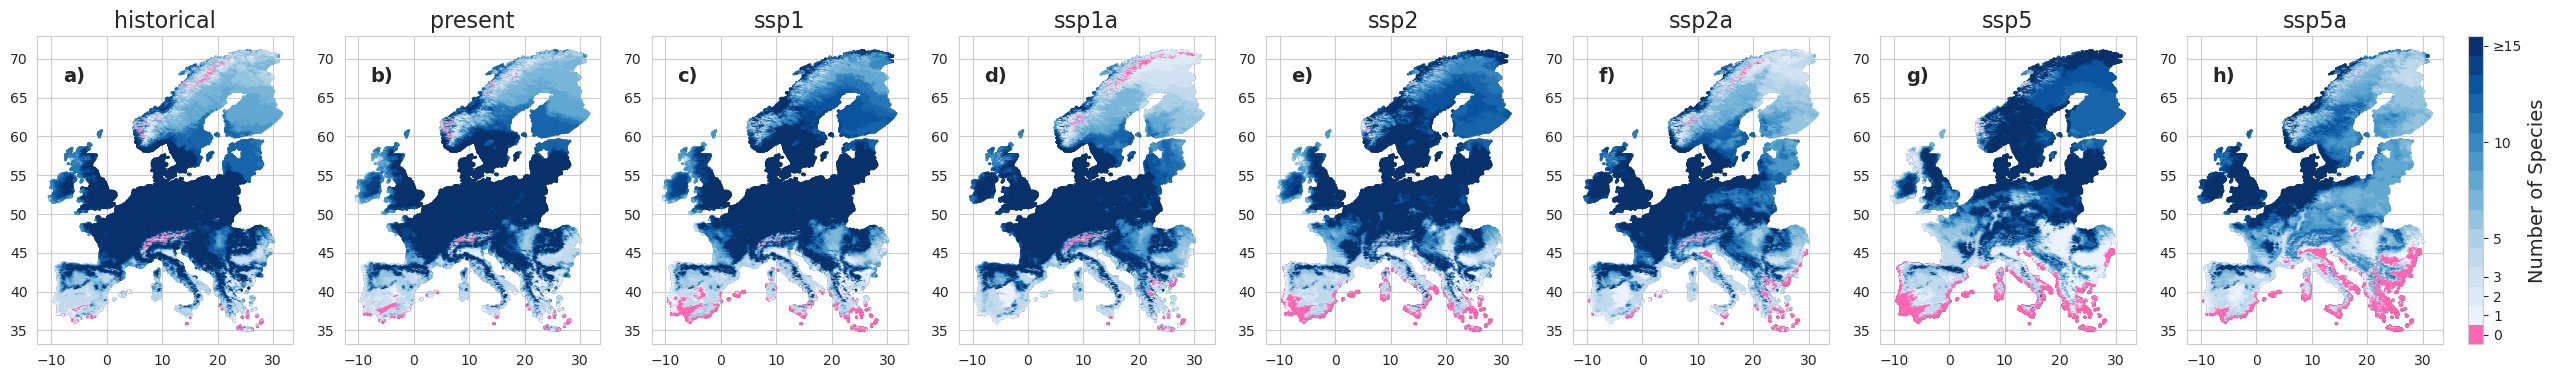

In [17]:
importlib.reload(amoc_plots)

fig, ax = plt.subplots(1, len(scenarios), figsize=(len(scenarios)*4, 4))
for i, scenario in enumerate(scenarios):
    ax[i].scatter(df_uncertainty['x'], df_uncertainty['y'], c=df_uncertainty[f'num_species_gt0_{scenario}'], cmap='viridis', vmin=0, vmax=10, s=1)
    sc = ax[i].scatter(
        df_uncertainty['x'],
        df_uncertainty['y'],
        c=df_uncertainty[f'num_species_gt0_{scenario}'],
        s=1,
        cmap=amoc_plots.blues_pink,
        norm=amoc_plots.blues_pink_norm_15
    )
    ax[i].set_title(scenario, fontsize=16)

    label = f"{chr(97 + i)})"  # chr(97) = 'a'
    ax[i].text(
        0.1, 0.9,                # X,Y position in axes coords (adjust as needed)
        label,
        transform=ax[i].transAxes, # Use axes coords
        fontsize=14,
        fontweight='bold',
        ha='left', va='top'
    )

vmin=0
vmax=15

boundaries = np.arange(vmin - 0.5, vmax + 1.5, 1)
# Colorbar with custom ticks
cbar = fig.colorbar(
    mpl.cm.ScalarMappable(cmap=amoc_plots.blues_pink, norm=amoc_plots.blues_pink_norm_15),
    ax=ax,
    boundaries=boundaries,
    orientation='vertical',
    fraction=0.02,
    pad=0.01
)
cbar.set_label('Number of Species', fontsize=14)

tick_values = [0, 1, 2, 3, 5, 10, 15]
cbar.set_ticks(tick_values)
cbar.set_ticklabels([str(v) if v < 15 else '≥15' for v in tick_values])

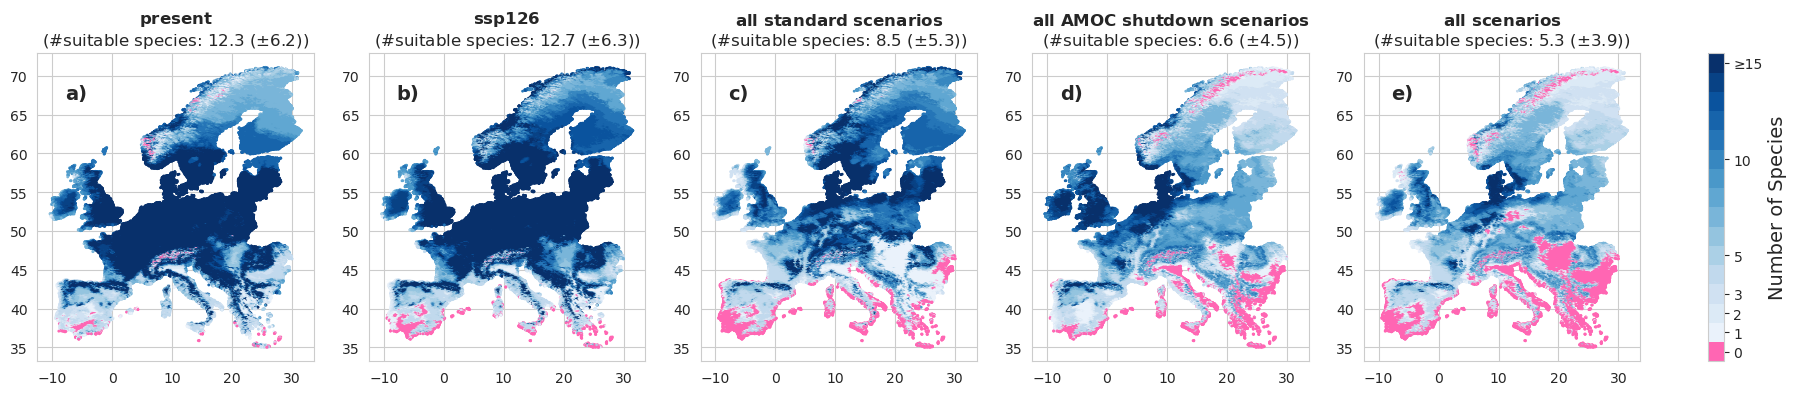

In [18]:
vmin = 0
vmax = 15

fig, ax = plt.subplots(1, len(col_list), figsize=(22, 4))

for i, (col, title) in enumerate(col_list.items()):
    values = df_uncertainty[col].to_numpy()
    sc = ax[i].scatter(
        df_uncertainty['x'],
        df_uncertainty['y'],
        c=values,
        s=1,
        cmap=amoc_plots.blues_pink,
        norm=amoc_plots.blues_pink_norm_15
    )
    ax[i].set_title(
        r'$\mathbf{' + title.replace(' ', r'\ ') + r'}$'
        + '\n'
        + f'(#suitable species: {total_weighted_means[col]:.1f} '
        + r'($\pm$'
        + f'{total_weighted_std[col]:.1f}))'
    )

    label = f"{chr(97 + i)})"  # chr(97) = 'a'
    ax[i].text(
        0.1, 0.9,                # X,Y position in axes coords (adjust as needed)
        label,
        transform=ax[i].transAxes, # Use axes coords
        fontsize=14,
        fontweight='bold',
        ha='left', va='top'
    )

boundaries = np.arange(vmin - 0.5, vmax + 1.5, 1)

cbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=amoc_plots.blues_pink_norm_15, cmap=amoc_plots.blues_pink),
    ax=ax,
    boundaries=boundaries,
    orientation='vertical',
    fraction=0.02,
    pad=0.04
)
cbar.set_label('Number of Species', fontsize=14)

tick_values = [0, 1, 2, 3, 5, 10, 15]
cbar.set_ticks(tick_values)
cbar.set_ticklabels([str(v) if v < 15 else '≥15' for v in tick_values])

plt.show()